# Regime-Aware Stochastic Equity Price Modelling with Heston Volatility and Machine-Learned Drift



## Goals and Challenges

The goal of this project is to model and generate plausible future return trajectories of a financial asset over a fixed time horizon. This is a challenging task due to the inherently non-stationary and stochastic nature of financial markets, limiting the effectiveness of more deterministic models depending on momentum or seasonal factors. 

This project focuses on mitigating these challenges by modelling regime changes, stochastic volatility and time-varying drift. The goal is to combine price factors, non-price and seasonal features, as well as calculating drift and volatility in a regime-aware framework to generate a better plausible forecast that reflects the evolving dynamics of the market. 

## Overview of Structure

### 1. Data Collection and Pre-Processing
Historical price data is obtained through the `yfinance` library, and transformed into log returns. Datasets are split into training data and testing data at this stage so as to avoid look ahead bias, with all further training of the model being done on the training set. Further transformations are done to extract price features such as 20 day moving average, bollinger bands, and German-Klass volatility. Other non-price factors such as EPS data, seasons, and earnings dates were also extracted. 

### 2. Regime Detection (Hidden Markov Model)
A Hidden Markov Model is fitted on hisorical returns to infer conditions of latent market regimes. These regimes capture changes in market behaviour based on regime and provide probabilistic information for further downstream analysis. 

### 3. Stochastic Volatility Modelling (Heston Model)
A Heston stochastic model is calibrated on training data to model volatility clustering and time-varying variance that wouldn't be present in a simplified model such as GBM. This provides a stochastic backbone for price evolution and ensures realistic volatility dynamics. 

### 4. Machine Learning Drift Modelling (XGBoost)
A supervised machine learning model is trained to estimate regime-dependent drift using engineered features and inferred regimes. Drift estimates are incorporated into the stochastic simulation using Bayesian confidence regularization.

### 5. Scenario Generation
The Heston model is combined with regime aware drift estimates to generate paths and prices through a Monte-Carlo process over the test time horizon. A representative medoid path is extracted for comparison with actual prices. 

### 6. Benchmarking and Evaluation
Models are compared against GARCH and GBM baselines using complementary metrics:
- Jensen–Shannon divergence on both distribution and medoid path
- Wasserstein distance
- RMSE
Evaluation was done using a walk-forward backtest across timeframes, including average and worst case scenarios

To demonstrate these models coming together, we will use SingTel (Z74.SI). 


In [1]:
'''
Importing functions
'''
from helper import load_data, test, metrics_summary, make_features, filter_feat, get_drift_corrected, bayesian_confidence,\
get_central_path, test_metrics
from ML import MLDrift
from benchmark import GBM, Garch
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from hmm_detect import HmmDetect
from options import calibrate_heston
import shap
import pandas as pd


/Users/sjegoh/Documents/GitHub/prediction_model/venv-pred_model/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Data Collection and Pre-Processing

In [2]:
'''
Loading in Data
'''
ticker = "Z74.SI"
split = 0.98
rfr = 0.02 # Risk-Free rate
n_paths = 40000 # number of runs for Monte-Carlo
t = yf.Ticker(ticker)
df = t.history(period = "10y", auto_adjust=True)

prices = df["Close"]
split = int(len(prices) * split)
df_train = df[:split]

train_price = prices[:split]
test_price = prices[split:]

log_train_ser = np.log(train_price/train_price.shift(1))
log_test_ser = np.log(test_price/test_price.shift(1))

log_train = log_train_ser.dropna().values
log_test = log_test_ser.dropna().values

P0 = test_price.iloc[0]
n_steps = len(log_test) # length of path to be simulated
q, feat = make_features(df_train, train_price, log_train_ser, t) # Makes features, q = annual dividend yield

feature_cols = [c for c in feat.columns if c != "logret"]
train_extra = feat[feature_cols].iloc[:-1].fillna(0).values


## 2. Regime Detection through use of Hidden Markov Model
A weakness of many naive models is the assumption that asset return dynamics are stationary over time, with drift and volatility remaining constant. In practice, many assets exhibit regime-dependent behaviour, where periods of low volatility and growth can alternate with episodes of high volatility and rapid price movements. 

To account for this non-stationarity, a Hidden Markov Model is employed to infer latent market conditions from historical return data. Rather than assigning regimes deterministically, this model allows us to produce probabilistic regime estimates, allowing us to incorporate uncertainty into  model. 

In [3]:
HMMdetector = HmmDetect(log_train, means = 3)
hmm_means = HMMdetector.model.means_.flatten()      
hmm_sds = np.sqrt(HMMdetector.model.covars_.flatten())

regimes_train = HMMdetector.model.predict(log_train.reshape(-1, 1)) # predicting regimes within training data
S_reg = HMMdetector.sim_reg_path(n_steps) # Simulate regimes for testing period


print(f"Probabilistic matrix: {HMMdetector.P}")
print(f"Mean Return: {HMMdetector.mu}")
print(f"Volatility of Return: {HMMdetector.sigma}")


Model is not converging.  Current: 7701.075584599889 is not greater than 7701.097101813755. Delta is -0.021517213865990925


Probabilistic matrix: [[1.52195862e-03 9.48493135e-01 4.99849066e-02]
 [9.98687254e-01 8.88218152e-04 4.24527550e-04]
 [1.50625878e-01 1.46881825e-01 7.02492298e-01]]
Mean Return: [7.90573107e-05 9.78627017e-05 1.71488640e-03]
Volatility of Return: [0.00880037 0.01066701 0.02625533]


## Explanation
Each row within the probabilistic matrix represents one regime, with each number inside being the probability it switches regimes. The 1st row (index 1) for example, consists of three numbbers, 0.9987, 0.0009, and 0.0004. This means, during this regime, there is a 99.87% chance the next regime will be the 0th row (index 0), a 0.09% chance it stays in its current regime, and a 0.04% chance it goes to the 2nd regime (index 2). During this regime, the mean log return is 0.000098 and the volatility is 0.01. 

We can see that the 0th row is a relatively calm regime, with the lowest log return of 0.000079 and volatility of 0.0088, the 2nd regime being the volatile, high growth regime with a mean log return of 0.0017 and a volatility of 0.026. The 1st regime is somewhere in between. 

# 3. Stochastic Volatility Modelling (Heston Model)
The Heston model improves on the General Brownian Motion by introducing a mean-reverting stochastic variance process, allowing volatility to evolve dynamically. This also enables us to model volatility clustering. Heston parameters are estimated through a quasi-MLE process using a discretized CIR process. 

- Kappa: Speed of mean reversion
- Theta: Long run variance
- Sigma: Volatility of volatility
- Rho: Correlation between price and volatility
- v0: Initial Variance

In [4]:
h, params = calibrate_heston(train_price, r = rfr, q = q)

# Finding expected price at end as sanity check
terminal, mc_call, _, _ = h.heston_fft_terminal_median(
    S0=P0,
    T=n_steps/252,
    q=q,
    )

print("Heston Params: ")
print(f"Kappa: {params[0]}")
print(f"Theta: {params[1]}")
print(f"Sigma: {params[2]}")
print(f"Rho: {params[3]}")
print(f"v0: {params[4]}")


Heston Params: 
Kappa: 3.7134040521524425
Theta: 0.03299882576865933
Sigma: 0.39189776316002545
Rho: 0.046799969388709645
v0: 0.033371669671576


In [5]:
_, v_tmp = h.simulate_paths(
    S0=P0,
    T=1.0,                
    steps=n_steps,
    n_paths=n_paths,
    q=q,
    mu_override=None
)

log_returns = np.diff(np.log(train_price.values))

annual_vol = log_returns.std() * np.sqrt(252)

model_annual_vol = np.mean(np.sqrt(v_tmp)) 

vol_scale = annual_vol / model_annual_vol

print(f"Volatility scale: {vol_scale}")
# Scale volatility to actual


Volatility scale: 1.0668673871451322


# 4. Machine Learning (XGBoost)
XGBoost is used to reduce noise from dataset and allow for easier feature filtering. Full list of engineered features are used to fit the model, and a shap analysis was run. Features with low SHAP values were filtered out to reduce noise, and another instance of the machine learning model was fitted with the filtered features. 

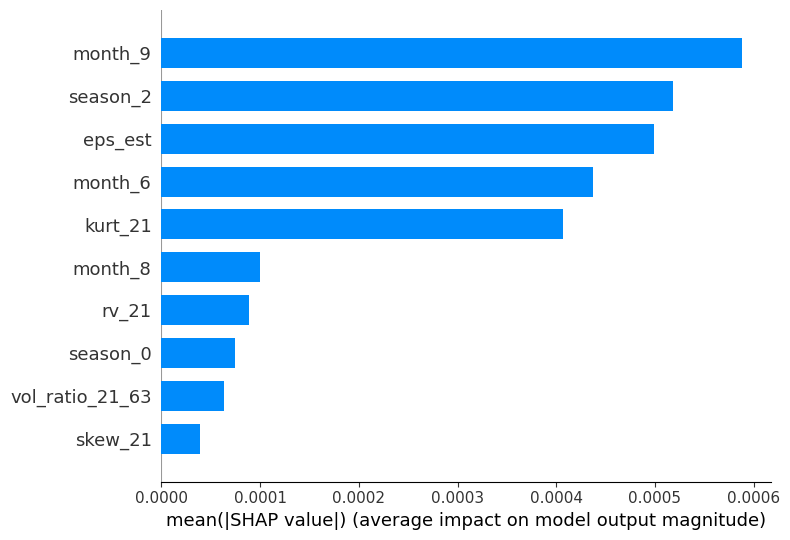

<Figure size 640x480 with 0 Axes>

In [6]:
ml_drift = MLDrift( # Initialize MLDrift object
    window = 20,
    n_regimes = HMMdetector.model.n_components
)

ml_drift.fit(log_train, regimes_train, train_extra) # Fit in training log prices, training regimes, and extra features


filtered_feat, cols = filter_feat(ml_drift.model,feature_cols, train_extra, feat, K = 10) 
explainer = shap.TreeExplainer(ml_drift.model)
shap_values = explainer.shap_values(filtered_feat, check_additivity = False)
shap.summary_plot(shap_values, cols, plot_type = "bar")
plt.tight_layout()
plt.show()





## Explanation
Evaluating the SHAP values, we can see that seasonal features play a large part in determining the drift of the asset. The two most significant factors are the 9th Month (September) and the 2nd season (June - September). This coincides with Singtel's annual half-year results release, signifying that these periods tend to alter regime conditions. This is also explained by the high SHAP value of EPS estimates, indicating that revisions in earnings estimates influence drift dynamics. 

Outside of seasonal factors, the rolling 21 day kurtosis also has a high SHAP value. Higher rolling kurtosis values reflect the presence of increased tail-risk, signifying increased tail risks in the current market. The model adjusts drift to account for this, reducing reliance on short term momentum and placing greater weight on regime and volatility structure. 

# 5. Scenario Generation
Machine-learned drift is regularised and confidence-weighted before going into the Heston model, which simulates 40,000 paths. A representative medoid is then selected, using the expected terminal price as a consistency check. 

In [7]:
# Scale down machine learning drift
drift_path_corrected = get_drift_corrected(ml_drift, log_train, regimes_train, filtered_feat, S_reg,
                                            hmm_means, hmm_sds)

# Apply ML predictions based on confidence
mu_eff = bayesian_confidence(HMMdetector, log_train, drift_path_corrected, n_steps)

log_S_paths, _ = h.simulate_paths(
    S0=P0,
    T=1.0,                
    steps=n_steps,
    n_paths=n_paths,
    q=q,
    mu_override=mu_eff,
    vol_scale = vol_scale
)

log_central_path, lower, upper = get_central_path(log_S_paths, np.log(P0), terminal = np.log(terminal))


# 6. Benchmarking and Evaluation
Results are compiled with `test_metrics` and compared with baseline GBM and GARCH(1, 1) models. 

In [14]:
actual_returns = np.diff(log_test)
model_metrics = test_metrics(actual_returns, log_S_paths, log_central_path)
central_path = np.exp(log_central_path)

GBM_model = GBM(log_returns.mean(), log_returns.std())
gbm_paths = GBM_model.simulate(S0 = P0, n_steps = n_steps, n_paths = n_paths)
gbm_central_path, gbm_lower, gbm_upper = get_central_path(gbm_paths, np.log(P0))
gbm_metrics = test_metrics(actual_returns, gbm_paths, gbm_central_path)
gbm_central_path = np.exp(gbm_central_path)

GARCH_model = Garch()
GARCH_model.fit(log_returns)
garch_paths = GARCH_model.simulate(S0 = P0, n_paths = n_paths, n_steps = n_steps)
garch_central_path, garch_lower, garch_upper = get_central_path(garch_paths, np.log(P0))
garch_metrics = test_metrics(actual_returns, garch_paths, garch_central_path)
garch_central_path = np.exp(garch_central_path)

print(f"Model: ")
print(f"JS (Medoid): {model_metrics[0]}")
print(f"JS (Dist): {model_metrics[1]}")
print(f"Wasserstein Distance: {model_metrics[2]}")
print(f"RMSE: {model_metrics[3]}\n")

print(f"GBM: ")
print(f"JS (Medoid): {gbm_metrics[0]}")
print(f"JS (Dist): {gbm_metrics[1]}")
print(f"Wasserstein Distance: {gbm_metrics[2]}")
print(f"RMSE: {gbm_metrics[3]}\n")

print(f"GARCH: ")
print(f"JS (Medoid): {garch_metrics[0]}")
print(f"JS (Dist): {garch_metrics[1]}")
print(f"Wasserstein Distance: {garch_metrics[2]}")
print(f"RMSE: {garch_metrics[3]}")


Model: 
JS (Medoid): 0.026739879229193193
JS (Dist): 0.19773943406230318
Wasserstein Distance: 0.0028059768158045766
RMSE: 0.01861458279866988

GBM: 
JS (Medoid): 0.07291173595341696
JS (Dist): 0.16358234085766923
Wasserstein Distance: 0.003236942276238831
RMSE: 0.017352719673120694

GARCH: 
JS (Medoid): 0.05657802514721011
JS (Dist): 0.18719898802410057
Wasserstein Distance: 0.004146442010873243
RMSE: 0.018134422773770933


## Evaluation
The model performs better in terms of Jensen-Shannon divergence on the medoid path and the Wasserstein distance, indicating that the representative trajectory generated by the model closely aliigns with realised returns that those produced by the GBM and GARCH baselines. However, the Jensen-Shannon divergence of the full return distribution is higher than both that of GBM and GARCH, indicating that the model generates a wider set of scenarios. This reflects the in introduction of regime-conditioned drift and stochastic volatility, increasing the distributional richness at the cost of tighter alignment with empirical return distribution. 

Note that this is one run on one time period, and is not representative of model performance as a whole. We will conduct a full backtest below. 

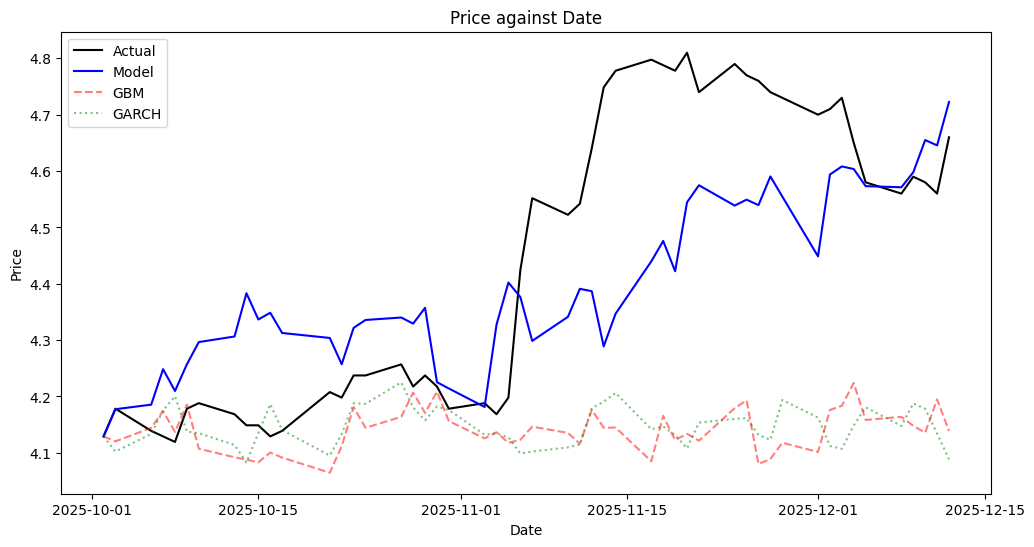

In [ ]:
plt.figure(figsize = (12, 6))
plt.plot(test_price.index, test_price.values, color = "black", label = "Actual")
plt.title("Price against Date")
plt.xlabel("Date")
plt.ylabel("Price")
plt.plot(test_price.index, central_path, color = "blue", label = "Model")
plt.plot(test_price.index, gbm_central_path, color = "red", linestyle = "--", label = "GBM", alpha = 0.5)
plt.plot(test_price.index, garch_central_path, color = "green", linestyle = ":", label = "GARCH", alpha = 0.5)
plt.legend()
plt.show()


# Walk Forward Validation + Actual Tests
Validation is done using NVidia (NVDA) over a ten-year period from 2015 - 2025, chosen due to the stock's exposure to multiple distinct market regimes. This interval encapsulates different structural phases, including the pre-AI boom, te COVID-19 crash and subsequent recovery, heightened trade and tariff uncertainty, and the AI valuation expansion. 

In [10]:
ticker = "NVDA"
split = 0.99
t = yf.Ticker(ticker)
df = t.history(period = "20y", auto_adjust=True)
    # walk forward validation 
l = len(df)
best_wass = float('inf')
best_wass_paths = None
best_wass_price = None
max_JS = float('-inf')
worst_paths = None
worst_price = None
min_JS = float('inf')
best_paths = None
best_price = None
model = pd.DataFrame(columns = ["JS_med", "JS_dist", "Wass", "RMSE"])
gbm = pd.DataFrame(columns = ["JS_med", "JS_dist", "Wass", "RMSE"])
garch = pd.DataFrame(columns = ["JS_med", "JS_dist", "Wass", "RMSE"])
count = 0
for i in range(0, l//2, int(l * (1 - split))):
    count += 1
    window_df = df.iloc[i:i + l//2]
    train_price, test_price, log_train_ser, log_test_ser, df_train = load_data(window_df, split=split)
    model_metrics, gbm_metrics, garch_metrics, paths, test_price = test(train_price, test_price, log_train_ser, log_test_ser, df_train, t)
    model.loc[len(model)] = model_metrics
    gbm.loc[len(gbm)] = gbm_metrics
    garch.loc[len(garch)] = garch_metrics
    if model_metrics[0] < min_JS:
        min_JS = model_metrics[0]
        best_paths = paths
        best_price = test_price
    if model_metrics[2] < min_JS:
        best_wass = model_metrics[2]
        best_wass_paths = paths
        best_wass_price = test_price
    if model_metrics[0] > max_JS:
        max_JS = model_metrics[0]
        worst_paths = paths
        worst_price = test_price
metric_df = pd.concat([metrics_summary(model, "Model"),metrics_summary(gbm, "GBM"), metrics_summary(garch, "GARCH")]).set_index("Model")

print(metric_df)



Model is not converging.  Current: 5527.965778616573 is not greater than 5527.968026340136. Delta is -0.0022477235634141834


      JS Medoid Mean  JS Medoid Max   JS Dist Mean  JS Dist Max  \
Model                                                             
Model  0.040 ± 0.031       0.111198  0.315 ± 0.080     0.553750   
GBM    0.045 ± 0.043       0.187629  0.236 ± 0.072     0.400926   
GARCH  0.054 ± 0.054       0.261393  0.247 ± 0.080     0.470247   

      Wasserstein Mean  Wasserstein Max      RMSE Mean  RMSE Max  
Model                                                             
Model    0.016 ± 0.009         0.050567  0.054 ± 0.016  0.099925  
GBM      0.019 ± 0.012         0.059549  0.045 ± 0.016  0.086604  
GARCH    0.019 ± 0.011         0.044020  0.045 ± 0.018  0.090939  


## Discussion of Results
The model continues to outperform in JS Medoid and Wasserstein distance, with a lower mean and standard deviation in both compared to GBM and GARCH. This suggests that the combination of a regime-aware program with time-varying stochastic drift improves the plausability of the central forecast. However, the JS Distribution remains higher than both GBM and GARCH. This reflects the trade-off a tight distribution for a more expressive model that aims to model realistic market scenarios. RMSE is notably higher due to both GBM and GARCH enforcing stationary drift or volatility dynamics, resulting in narrower but less-responsive forecasts. 

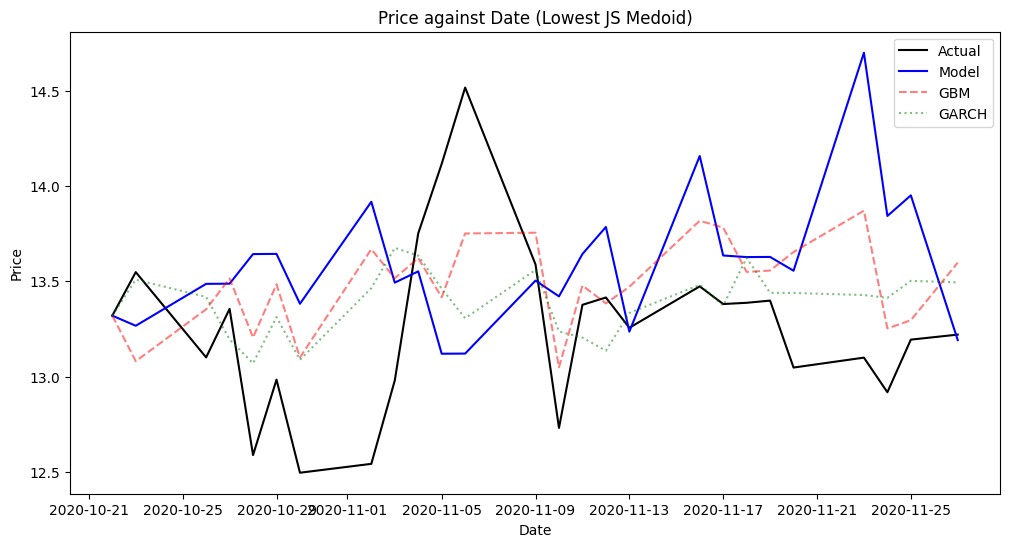

In [19]:
plt.figure(figsize = (12, 6))
plt.plot(best_price.index, best_price.values, color = "black", label = "Actual")
plt.plot(best_price.index, best_paths[0], color = "blue", label = "Model")
plt.plot(best_price.index, best_paths[1], color = "red", linestyle = "--", label = "GBM", alpha = 0.5)
plt.plot(best_price.index, best_paths[2], color = "green", linestyle = ":", label = "GARCH", alpha = 0.5)
plt.title("Price against Date (Lowest JS Medoid)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


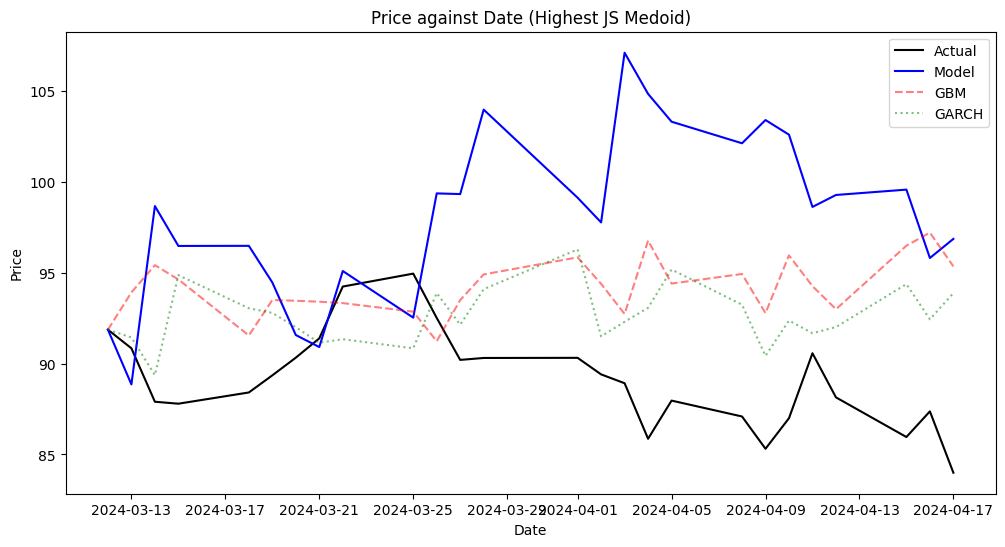

In [18]:
plt.figure(figsize = (12, 6))
plt.plot(worst_price.index, worst_price.values, color = "black", label = "Actual")
plt.plot(worst_price.index, worst_paths[0], color = "blue", label = "Model")
plt.plot(worst_price.index, worst_paths[1], color = "red", linestyle = "--", label = "GBM", alpha = 0.5)
plt.plot(worst_price.index, worst_paths[2], color = "green", linestyle = ":", label = "GARCH", alpha = 0.5)
plt.title("Price against Date (Highest JS Medoid)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


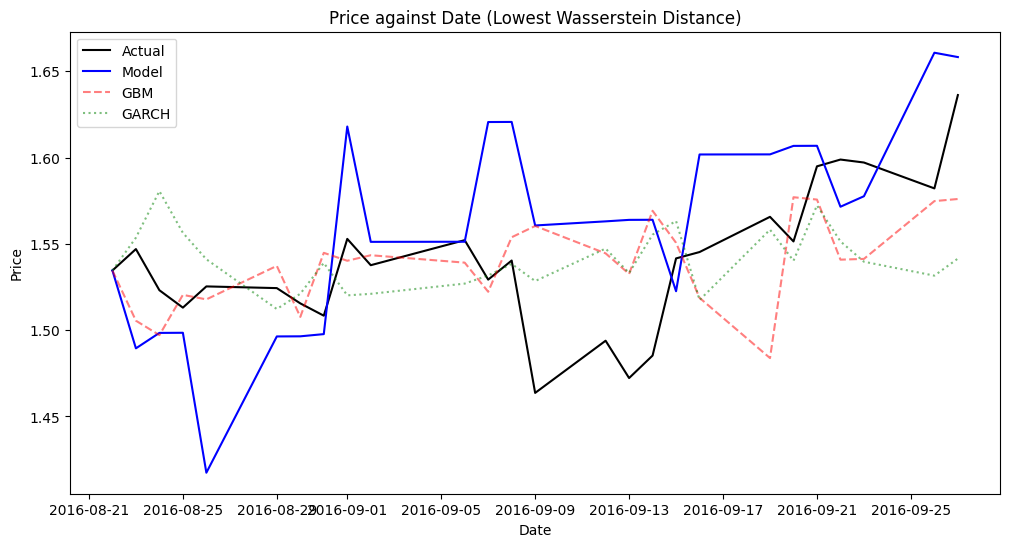

In [17]:
plt.figure(figsize = (12, 6))
plt.plot(best_wass_price.index, best_wass_price.values, color = "black", label = "Actual")
plt.plot(best_wass_price.index, best_wass_paths[0], color = "blue", label = "Model")
plt.plot(best_wass_price.index, best_wass_paths[1], color = "red", linestyle = "--", label = "GBM", alpha = 0.5)
plt.plot(best_wass_price.index, best_wass_paths[2], color = "green", linestyle = ":", label = "GARCH", alpha = 0.5)
plt.title("Price against Date (Lowest Wasserstein Distance)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


# Final Discussion
This project sets out to generate plausible asset forecasts under non-stationary market conditions. It employs a Hidden Markov Model to recognize different regimes and conditions under said regimes, stochastic volatility through a Heston model, and machine-learned, regime-aware drift estimation. 

Evaluation using walk-forward validation on NVDA demonstrates that the model consistently produces medoid curves more representative of actual results, as shown by the low Jensen-Shannon Divergence on Medoid (0.040) Wasserstein Distance (0.016). However, the model also generates a broader range of outcomes, leading to a higher Jensen-Shannon Divergence on distribution (0.315) as compared to GBM (0.236) and GARCH (0.247). This reflects a classic bias-variance trade-off, with the model achieving a closer medoid while sacrificing some distributional tightness. 

Overall, the results suggest that while the model may underperform in terms of RMSE and distributional Jensen-Shannon divergence, it provides a more expressive and interpretable simulation that enables better understanding of future market behaviour under regime shifts. 

## Limitations 
Several limitations and assumptions should be noted. 

The Hidden Markov Model assumes the market consists of a fixed number of latent regimes and that the probability of the next regime depends solely on the current one. While effective for capturing persistent market states, this assumption may oversimplify more complex or rapidly evolving market conditions. This makes it more suitable for forecasting near-term future dynamics, as long term these assumptions may break down.

The model places primary emphasis on asset-local features when estimating drift, under the assumption that near-term market dynamics are largely reflected in price behaviour, regime structure, and related statistical measures. While this enables more expressive and responsive scenario generation, it also increases sensitivity to shocks that are not captured by asset-specific features. Divergence can also increase when external events induce abrupt structural regime changes, as observed in the worse-case NVDA scenario. 

The stochastic volatility and machine-learned drift components are calibrated on historical data and assume the stability of such dynamics throughout the forecast horizon. As a result, rapidly evolving regimes or structural changes in volatility dyamics during the forecasting window may not be reflected in simulated forecasts. 